# Abbe image formation: diffraction orders, pupil cutoff and partial coherence

Ernst Abbe explained in 1873 why a microscope objective has a resolution
limit that no magnification can beat: the object diffracts the illuminating
light into orders, the objective collects only those inside its aperture,
and the image is the interference of what was collected. A structure whose
first diffraction orders miss the aperture leaves no trace in the image.
With oblique light the limit moves from $\lambda/\mathrm{NA}$ to
$\lambda/(\mathrm{NA} + \mathrm{NA}_c)$, and the condenser aperture
$\mathrm{NA}_c$ decides how coherent the image is.

This notebook is the first of a series on microscopy; the next ones build
on it:

| Notebook | Topic |
|---|---|
| **52** | Abbe image formation (this one) |
| [53](53_phase_contrast_dic.ipynb) | Zernike phase contrast and DIC for transparent objects |
| [54](54_confocal_microscopy.ipynb) | confocal microscopy: pinhole, PSF product, optical sectioning |
| [55](55_fourier_ptychography.ipynb) | Fourier ptychography: synthetic aperture from an LED array |
| [27](27_holographic_microscopy.ipynb) | digital holographic microscopy (quantitative phase) |

Everything here uses `pyoptics.microscopy`:

| Function | Purpose |
|---|---|
| `source_points()` | the condenser aperture (Köhler illumination) as plane waves on the frequency grid |
| `pupil()` | the objective pupil with defocus and masks |
| `abbe_image()` | the partially coherent image as a sum of coherent images, one per source point |
| `weak_object_transfer()` | amplitude and phase transfer functions of weak objects |
| `grating_cutoff()` | the smallest period that is imaged, $\lambda/(\mathrm{NA}+\mathrm{NA}_c)$ |

The drawings of the setups come from
`pyoptics.sketch` (thin lenses and paraxially traced rays). The sections:

0. the microscope: Köhler illumination and Abbe's picture of the back
   focal plane,
1. a grating, its diffraction orders and the pupil,
2. Abbe's and Porter's experiments: filtering orders in the back focal plane,
3. oblique illumination and the transfer of fine gratings vs. $\sigma$,
   against the coherent transfer function and the incoherent MTF,
4. coherent vs. partially coherent images of edges and of two pinholes,
5. why a transparent object is invisible in focus, and how defocus and
   oblique illumination make its phase visible (the start of notebook 53).

Conventions: scalar fields varying as $e^{i(\mathbf{k}\cdot\mathbf{r} - \omega t)}$,
thin objects with the complex transmission $t(x, y)$, lengths in micrometres
in object space (the magnification is left out). The objective passes the
transverse wave vectors $|\mathbf{k}_\perp| \le k_0\,\mathrm{NA}$ with
$k_0 = 2\pi/\lambda$; the partial coherence factor is
$\sigma = \mathrm{NA}_c/\mathrm{NA}$. Coherent and incoherent imaging of
self-luminous objects, the CTF and OTF, are in notebooks
[15](15_imaging_zernikes.ipynb) and [17](17_psf_mtf_strehl.ipynb); the same
Abbe sum drives the lithography notebooks from [31](31_vectorial_imaging_lithography.ipynb)
on, and Hopkins' alternative is in [34](34_hopkins_socs.ipynb).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from pyoptics import microscopy as mic
from pyoptics.fft import FT, inv_FT
from pyoptics.utils import grid2d, freq_grid

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})
t_start = time.time()

wl = 0.55                   # green light, um
NA = 0.65                   # 40x dry objective
k0 = 2*np.pi/wl
N, dx = 256, 0.1            # dx <= wl/(4 NA) = 0.21 um samples the image intensity
L = N*dx
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
K_x, K_y = freq_grid(x, y)
extent = (x[0], x[-1], y[0], y[-1])
na_extent = (K_x[0, 0]/k0, K_x[0, -1]/k0, K_y[0, 0]/k0, K_y[-1, 0]/k0)
print(f"lambda/NA = {wl/NA:.3f} um, lambda/(2 NA) = {wl/(2*NA):.3f} um, field {L:.1f} um, "
      f"pupil radius {k0*NA/(2*np.pi/L):.1f} frequency samples")


def show(ax, img, title, cmap="gray", ext=extent, colorbar=True, **kwargs):
    im = ax.imshow(img, extent=ext, cmap=cmap, **kwargs)
    ax.set_title(title)
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im


def pupil_circle(ax, NA_=NA, **kwargs):
    kw = dict(fill=False, color="tab:red", lw=1.5)
    kw.update(kwargs)
    ax.add_patch(Circle((0, 0), NA_, **kw))

lambda/NA = 0.846 um, lambda/(2 NA) = 0.423 um, field 25.6 um, pupil radius 30.3 frequency samples


## 0. The microscope

A transmitted light microscope with Köhler illumination (1893), drawn
unfolded along one axis. The collector images the lamp filament into the
condenser aperture diaphragm, which sits in the front focal plane of the
condenser; every point of the filament therefore leaves the condenser as a
**plane wave** through the specimen (orange), and its direction is set by
the position of the point in the aperture diaphragm. The condenser images
the field diaphragm into the specimen and limits the illuminated field.
The objective and tube lens image each point of the specimen onto the
camera (blue), and the objective focuses each plane wave to a point of its
back focal plane, the pupil, where the image of the aperture diaphragm
appears.

Two sets of conjugate planes follow: **aperture planes** (A: filament,
condenser aperture, back focal plane), where the angles live, and **field
planes** (F: field diaphragm, specimen, camera), where the positions live.
Opening the aperture diaphragm increases the condenser NA, $\mathrm{NA}_c$,
and the range of illumination directions; that is the knob $\sigma$ of the
simulations below.

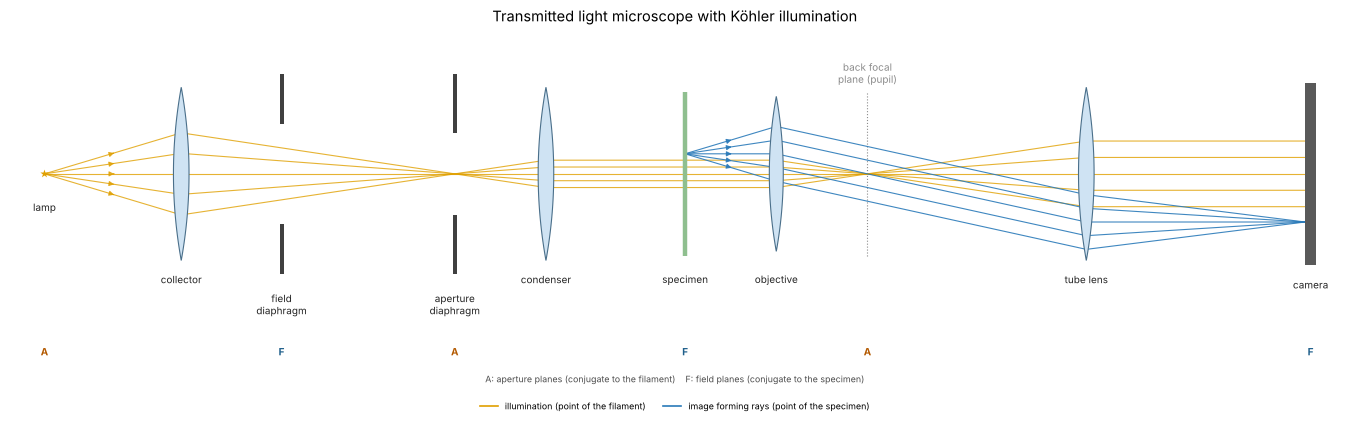

In [2]:
from pyoptics import sketch

fig, ax = plt.subplots(figsize=(17, 5.6))
sketch.koehler_microscope(ax, title="Transmitted light microscope with Köhler illumination")
plt.tight_layout()

Abbe's picture is the right half of this layout, simplified to a 4f
system: a grating in the front focal plane of the objective diffracts the
plane wave of one source point into orders, the objective focuses each
order into one point of the back focal plane, and the tube lens lets the
orders interfere in the image plane. A stop in the back focal plane
decides which orders take part (right: the $\pm 2$nd orders blocked; the
image then lacks the corresponding fine detail).

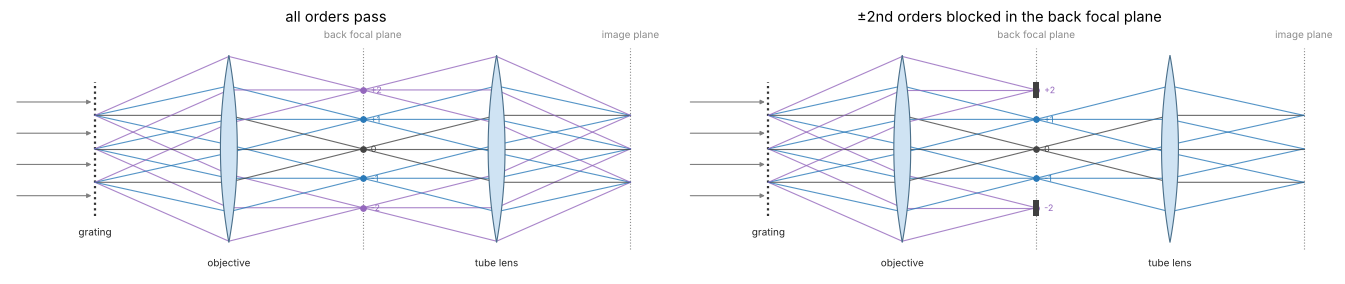

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.4))
sketch.abbe_4f(axes[0], title="all orders pass")
sketch.abbe_4f(axes[1], blocked=(-2, 2), title="±2nd orders blocked in the back focal plane")
plt.tight_layout()

## 1. Diffraction orders and the pupil

A line grating of period $p$ diffracts a plane wave into orders with
$\sin\theta_m = m\lambda/p$, i.e. transverse wave vectors
$k_{x,m} = 2\pi m/p$: its spectrum is a row of delta peaks. In the back focal
plane of the objective these orders appear as points, and the aperture
stop (the pupil) is a disk of radius $\mathrm{NA}$ in the coordinates
$k_x/k_0$. With axial, coherent illumination the image is the Fourier
synthesis of the orders inside the disk:

$$I(x) = \Big|\sum_{|m|\lambda/p \le \mathrm{NA}} c_m\, e^{2\pi i m x/p}\Big|^2 .$$

A binary amplitude grating with a duty cycle of 1/2 (Ronchi ruling) has
$c_0 = 1/2$, $c_m = \sin(m\pi/2)/(m\pi)$: only odd orders. Below the period
$\lambda/\mathrm{NA} = 0.85$ µm only the zero order passes, and the image is
uniformly grey: the grating is not resolved, however much the image is
magnified. Periods are chosen as fractions of the window, so the orders
fall on the frequency grid.

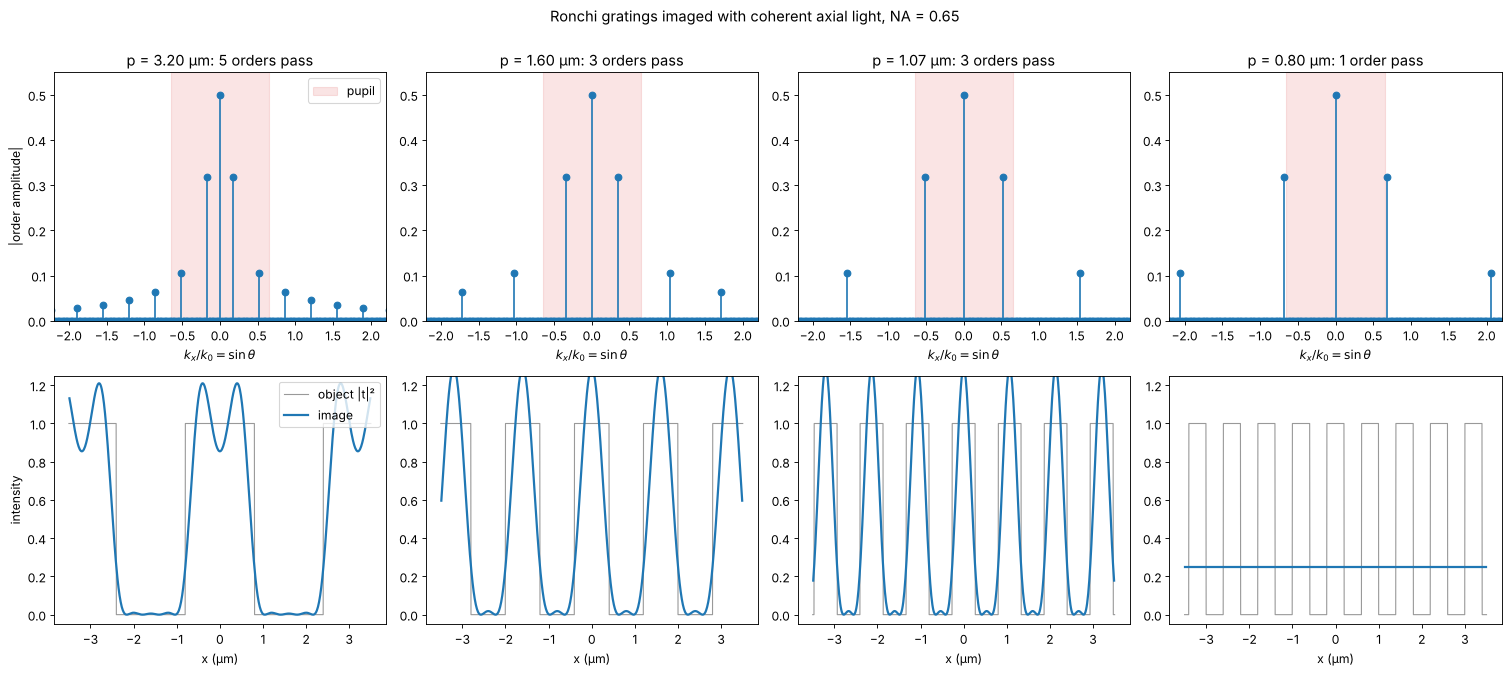

In [4]:
ix = np.arange(N)
IX, IY = np.meshgrid(ix, ix)


def ronchi(p, x_=None):
    # bars of width p/2 centred at x = 0, p, 2p, ... as a Fourier series with all
    # orders below the Nyquist frequency (n periods across the window, so the
    # orders fall on the frequency grid, and no aliased harmonics); with x_ the
    # ideal square wave for plotting
    if x_ is not None:
        return (np.mod(x_/p + 0.25, 1) < 0.5).astype(float)
    n = int(round(L/p))
    t = 0.5*np.ones((N, N))
    for m in range(1, (N//2 - 1)//n + 1):
        t += 2*np.sin(m*np.pi/2)/(m*np.pi)*np.cos(2*np.pi*m*n*X/L)
    return t


def fine(row, factor=8):
    # band limited intensity rows (|f| <= 2 NA/lambda < 1/(2 dx)) can be Fourier interpolated
    from scipy.signal import resample
    return np.linspace(x[0], x[0] + L, N*factor, endpoint=False), resample(row, N*factor)


periods = [L/8, L/16, L/24, L/32]      # 3.2, 1.6, 1.07, 0.8 um
xs = np.linspace(-3.5, 3.5, 1401)
fig, axes = plt.subplots(2, 4, figsize=(19, 8.4))
cut = (np.abs(x) < 3.5)
for j, p in enumerate(periods):
    obj = ronchi(p)
    S = np.abs(FT(obj))/N**2
    ax = axes[0, j]
    row = S[N//2]
    ax.stem(K_x[0]/k0, row, basefmt=" ")
    ax.axvspan(-NA, NA, color="tab:red", alpha=0.12, label="pupil")
    n_pass = int(np.sum(row[np.abs(K_x[0]) <= k0*NA] > 1e-3))
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(0, 0.55)
    ax.set_xlabel(r"$k_x/k_0 = \sin\theta$"); ax.set_title(f"p = {p:.2f} µm: {n_pass} order{'s' if n_pass > 1 else ''} pass")
    if j == 0:
        ax.set_ylabel("|order amplitude|"); ax.legend(loc="upper right")
    I = mic.abbe_image(obj, x, y, wl, NA)
    ax = axes[1, j]
    ax.plot(xs, ronchi(p, xs), color="0.6", lw=1, label="object |t|²")
    xf, If = fine(I[N//2])
    ax.plot(xf[np.abs(xf) < 3.5], If[np.abs(xf) < 3.5], color="tab:blue", lw=2, label="image")
    ax.set_xlabel("x (µm)"); ax.set_ylim(-0.05, 1.25)
    if j == 0:
        ax.legend(loc="upper right"); ax.set_ylabel("intensity")
fig.suptitle(f"Ronchi gratings imaged with coherent axial light, NA = {NA}", y=1.0)
plt.tight_layout()

With 3 orders the image is $|c_0 + 2c_1\cos(2\pi x/p)|^2$, rounded bars
without the sharp edges; more orders bring back the edges with the familiar
Gibbs ringing of a truncated Fourier series. The image depends on the
**amplitudes and phases of the orders that pass**, not on the object
directly. That is the core of Abbe's theory.

## 2. Abbe's and Porter's experiments: filtering in the back focal plane

Abbe demonstrated his theory by placing masks in the back focal plane; Porter
(1906) made it a classic with a wire mesh. The object here is a mesh of
vertical and horizontal bars (periods 1.6 µm and 2.13 µm). Its spectrum is
a 2D lattice of orders. Filters in the pupil:

- full pupil: the mesh,
- a horizontal slit: only orders with $k_y \approx 0$ pass, so only the
  vertical bars remain,
- a vertical slit: only the horizontal bars,
- zero order blocked: dark field, the edges light up and the contrast
  reverses,
- only the $\pm 1$st orders along $x$ (the zero order blocked as well):
  $|e^{2\pi i x/p} + e^{-2\pi i x/p}|^2 = 4\cos^2(2\pi x/p)$, the image
  shows twice as many lines as the object has. The image faithfully
  represents the orders, not the object.

The same filtering cleans laser beams: in a spatial filter a lens puts the
angular spectrum of the beam into its back focal plane, and a pinhole there
passes only the clean Gaussian on the axis (notebook
[56](56_gaussian_beam_decomposition.ipynb)).

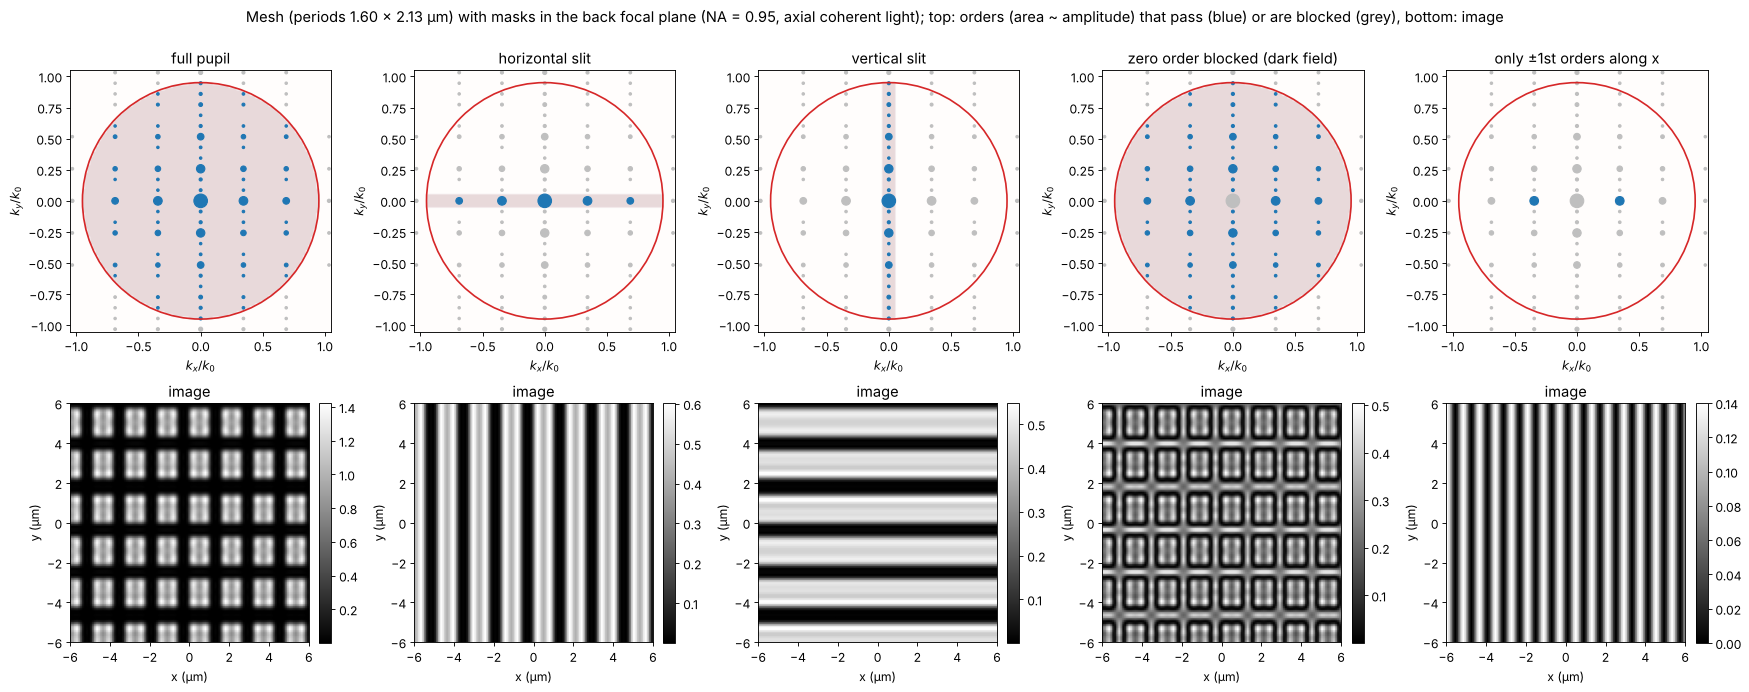

In [5]:
p_x, p_y = L/16, L/12
mesh = ((np.mod(IX*16, N) < 0.65*N) & (np.mod(IY*12, N) < 0.7*N)).astype(float)
NA_wide = 0.95                         # a dry high NA objective lets more orders through
fx, fy = K_x/k0, K_y/k0
q1 = wl/p_x                            # first order along x in NA units
filters = {
    "full pupil": np.ones_like(fx),
    "horizontal slit": (np.abs(fy) < 0.05).astype(float),
    "vertical slit": (np.abs(fx) < 0.05).astype(float),
    "zero order blocked (dark field)": (np.hypot(fx, fy) > 0.03).astype(float),
    "only ±1st orders along x": ((np.abs(fy) < 0.03)
                                 & (np.abs(np.abs(fx) - q1) < 0.03)).astype(float),
}
fig, axes = plt.subplots(2, 5, figsize=(22, 8.6))
zoom = (-6, 6, -6, 6)
sel = np.ix_(np.abs(y) < 6, np.abs(x) < 6)
S_mesh = np.abs(FT(mesh))/N**2
orders = S_mesh > 2e-3                 # the diffraction orders of the mesh
for j, (name, F) in enumerate(filters.items()):
    P = mic.pupil(x, y, wl, NA_wide, mask=F)
    I = mic.abbe_image(mesh, x, y, wl, NA_wide, P=P)
    ax = axes[0, j]
    passed = orders & (np.abs(P) > 0)
    blocked = orders & ~passed
    ax.scatter(fx[blocked], fy[blocked], s=4 + 300*S_mesh[blocked], color="0.75")
    ax.scatter(fx[passed], fy[passed], s=4 + 300*S_mesh[passed], color="tab:blue")
    ax.imshow(np.abs(P) > 0, extent=na_extent, cmap="Reds", alpha=0.15, vmin=0, vmax=1)
    ax.set_title(name)
    pupil_circle(ax, NA_wide)
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel(r"$k_x/k_0$"); ax.set_ylabel(r"$k_y/k_0$")
    show(axes[1, j], I[sel], "image", ext=zoom, colorbar=True)
    axes[1, j].set_xlabel("x (µm)"); axes[1, j].set_ylabel("y (µm)")
fig.suptitle(f"Mesh (periods {p_x:.2f} × {p_y:.2f} µm) with masks in the back focal plane "
             f"(NA = {NA_wide}, axial coherent light); top: orders (area ~ amplitude) that pass "
             f"(blue) or are blocked (grey), bottom: image", y=1.0)
plt.tight_layout()

## 3. Oblique illumination and the transfer of fine gratings

With a single plane wave at the illumination direction
$\mathrm{NA}_c = \sin\theta_c$, every order shifts by $\mathrm{NA}_c$ in the
pupil. The zero order moves towards the edge, and a first order on the
other side still fits in as long as
$\lambda/p \le \mathrm{NA} + \mathrm{NA}_c$. A full condenser ($\sigma = 1$)
contains all directions up to $\mathrm{NA}$, so the finest period imaged is
$\lambda/(2\mathrm{NA}) = 0.42$ µm. Köhler illumination makes each point of
the condenser aperture a plane wave through the object; the waves from
different points are mutually incoherent, so their images add in intensity
(`abbe_image()`).

For a weak amplitude grating $t = 1 + a\cos(2\pi x/p)$ the image is
$I = 1 + a\,H_a(1/p)\cos(2\pi x/p)$. `weak_object_transfer()` computes
$H_a$ from the overlap of the shifted pupil with the condenser aperture
(Hopkins' transmission cross coefficient with one argument at zero). Two limits are
analytic:

- $\sigma = 0$: $H_a = 2$ up to the cutoff $\mathrm{NA}/\lambda$, the coherent
  transfer function (a step),
- $\sigma = 1$: $H_a/2$ is the overlap area of two disks, the incoherent
  MTF $\frac{2}{\pi}\left(\arccos q - q\sqrt{1-q^2}\right)$ with
  $q = \lambda f/(2\mathrm{NA})$, reaching up to $2\mathrm{NA}/\lambda$.

In between, the transfer is flat at low frequencies (coherent like) and
falls to zero at $(1 + \sigma)\mathrm{NA}/\lambda$. The markers are the
contrasts of full `abbe_image()` simulations of weak gratings.

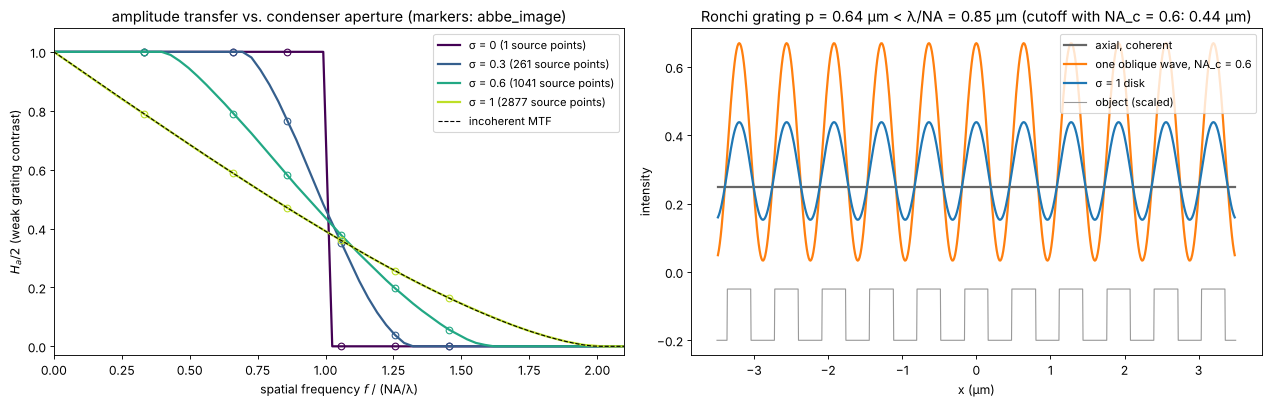

In [6]:
sigmas = [0.0, 0.3, 0.6, 1.0]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(sigmas)))
f = K_x[0]/(2*np.pi)                   # spatial frequency, cycles/um
pos = f >= 0
fc = NA/wl
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
ax = axes[0]
a = 0.02
for s, c in zip(sigmas, colors):
    src = mic.source_points(x, y, wl, s*NA)
    H_a, H_phi = mic.weak_object_transfer(x, y, wl, NA, source=src)
    ax.plot(f[pos]/fc, np.real(H_a[N//2, pos])/2, color=c, lw=2, label=f"σ = {s:g} ({len(src[2])} source points)")
    # full simulations at a few periods
    for n_per in [10, 20, 26, 32, 38, 44]:
        p = L/n_per
        if 1/p > 2.05*fc:
            continue
        I = mic.abbe_image(1 + a*np.cos(2*np.pi*X/p), x, y, wl, NA, source=src)
        ax.plot(1/p/fc, (I.max() - I.min())/2/a/2, "o", color=c, ms=6, mfc="none")
q = np.clip(f[pos]/(2*fc), 0, 1)
ax.plot(f[pos]/fc, 2/np.pi*(np.arccos(q) - q*np.sqrt(1 - q**2)), "k--", lw=1, label="incoherent MTF")
ax.set_xlim(0, 2.1); ax.set_ylim(-0.03, 1.08)
ax.set_xlabel(r"spatial frequency $f$ / (NA/λ)"); ax.set_ylabel(r"$H_a/2$ (weak grating contrast)")
ax.set_title("amplitude transfer vs. condenser aperture (markers: abbe_image)")
ax.legend(loc="upper right", fontsize=10)

# one oblique plane wave, a grating below lambda/NA
ax = axes[1]
p = L/40                               # 0.64 um < lambda/NA = 0.85 um
obj = ronchi(p)
cases = [("axial, coherent", mic.source_points(x, y, wl, 0.0)),
         ("one oblique wave, NA_c = 0.6", mic.source_points(x, y, wl, 0.0, points=[(-0.6, 0)])),
         ("σ = 1 disk", mic.source_points(x, y, wl, NA, step=2))]
for (name, src), c in zip(cases, ["0.4", "tab:orange", "tab:blue"]):
    I = mic.abbe_image(obj, x, y, wl, NA, source=src)
    xf, If = fine(I[N//2])
    ax.plot(xf[np.abs(xf) < 3.5], If[np.abs(xf) < 3.5], lw=2, color=c, label=name)
ax.plot(xs, ronchi(p, xs)*0.15 - 0.2, color="0.6", lw=1, label="object (scaled)")
ax.set_xlabel("x (µm)"); ax.set_ylabel("intensity")
ax.set_title(f"Ronchi grating p = {p:.2f} µm < λ/NA = {wl/NA:.2f} µm "
             f"(cutoff with NA_c = 0.6: {mic.grating_cutoff(wl, NA, 0.6):.2f} µm)")
ax.legend(loc="upper right", fontsize=10)
plt.tight_layout()

The single oblique wave resolves the grating with high contrast: the zero
and one first order pass, at the price of an asymmetric pupil that would
image a defocused grating with a lateral shift. The full condenser gives a
lower but symmetric contrast. This is why microscopists close the aperture
diaphragm only to about $\sigma \approx 0.7$ to $0.8$: a compromise
between resolution (wide condenser) and contrast and depth of field
(narrow condenser).

## 4. Coherent vs. partially coherent images

The degree of coherence shows best at edges and in the classic two point
test. The object is an opaque screen with an edge, and two pinholes much
smaller than the resolution. For comparison, the "incoherent" curve is the image of
self-luminous (fluorescent) points: the sum of the two intensity PSFs.

- **Edge.** Coherent light ($\sigma = 0$) rings, overshoots by 18 % and
  crosses the edge at 1/4 of the clear intensity (amplitude 1/2); with
  rising $\sigma$ the ringing fades and the image approaches the
  incoherent edge, which crosses at 1/2.
- **Two points.** With coherent light the two point amplitudes interfere:
  in phase they fill the gap between them and need a larger distance to
  show a dip than incoherent points at the Rayleigh distance
  $0.61\lambda/\mathrm{NA}$; the same distance gives a clear dip for
  $\sigma = 1$.

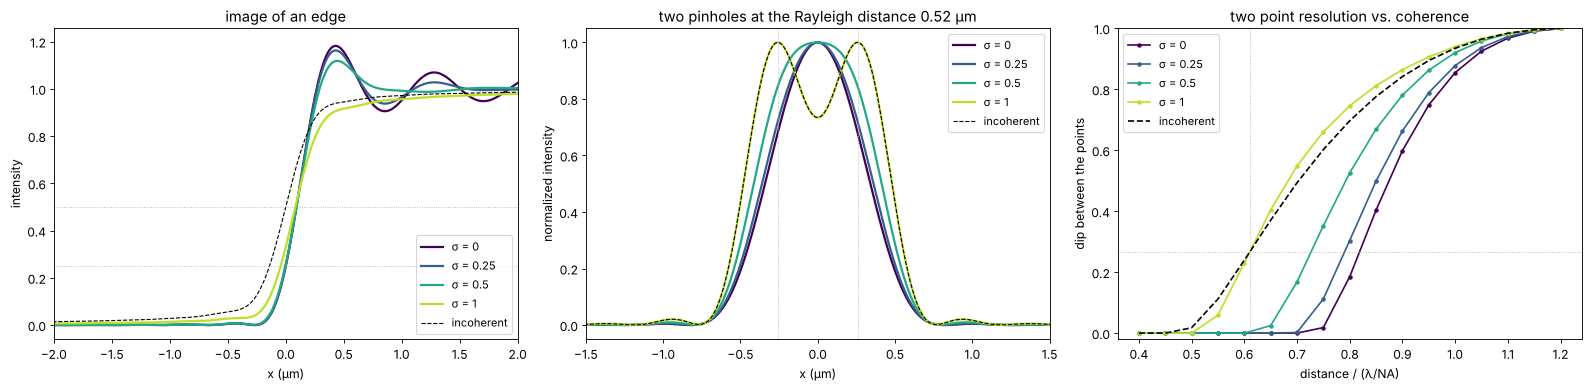

In [7]:
sigmas_e = [0.0, 0.25, 0.5, 1.0]
edge = (X > 0) + 0.5*(np.abs(X) < dx/2)   # edge at x = 0 (half value on the sample)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.0))
ax = axes[0]
for s, c in zip(sigmas_e, colors):
    src = mic.source_points(x, y, wl, s*NA, step=2)
    I = mic.abbe_image(edge, x, y, wl, NA, source=src)
    ax.plot(*fine(I[N//2]), color=c, lw=2, label=f"σ = {s:g}")
# incoherent edge: the edge convolved with the intensity PSF (OTF of the clear pupil)
P0 = mic.pupil(x, y, wl, NA)
psf_I = np.abs(inv_FT(P0))**2
psf_I /= psf_I.sum()
I_inc = np.real(inv_FT(FT(edge)*FT(psf_I)))
ax.plot(*fine(I_inc[N//2]), "k--", lw=1, label="incoherent")
ax.axhline(0.25, color="0.7", lw=0.8, ls=":"); ax.axhline(0.5, color="0.7", lw=0.8, ls=":")
ax.set_xlim(-2, 2); ax.set_xlabel("x (µm)"); ax.set_ylabel("intensity")
ax.set_title("image of an edge"); ax.legend(loc="lower right", fontsize=10)

d_rayleigh = 0.61*wl/NA


def two_holes(d):
    # two point-like holes at x = -d/2, +d/2, at any distance: their spectrum is
    # exp(-i k_x x_j) on the grid (band limited delta functions)
    return inv_FT(np.exp(-0.5j*K_x*d) + np.exp(0.5j*K_x*d))


def dip(I_row, d):
    xf, If = fine(I_row)
    centre = If[np.argmin(np.abs(xf))]
    peak = np.max(If[np.abs(xf) <= d])
    return 1 - centre/peak


ax = axes[1]
for s, c in zip(sigmas_e, colors):
    src = mic.source_points(x, y, wl, s*NA, step=2)
    I = mic.abbe_image(two_holes(d_rayleigh), x, y, wl, NA, source=src)
    xf, If = fine(I[N//2])
    ax.plot(xf, If/If.max(), color=c, lw=2, label=f"σ = {s:g}")


def incoherent_points(d):
    # self-luminous points: the sum of the two shifted intensity PSFs
    return np.real(inv_FT(FT(psf_I)*(np.exp(-0.5j*K_x*d) + np.exp(0.5j*K_x*d))))


xf, If = fine(incoherent_points(d_rayleigh)[N//2])
ax.plot(xf, If/If.max(), "k--", lw=1, label="incoherent")
for xs in (-d_rayleigh/2, d_rayleigh/2):
    ax.axvline(xs, color="0.7", lw=0.8, ls=":")
ax.set_xlim(-1.5, 1.5); ax.set_xlabel("x (µm)"); ax.set_ylabel("normalized intensity")
ax.set_title(f"two pinholes at the Rayleigh distance {d_rayleigh:.2f} µm")
ax.legend(loc="upper right", fontsize=10)

ax = axes[2]
ds = np.linspace(0.4, 1.2, 17)*wl/NA
for s, c in zip(sigmas_e, colors):
    src = mic.source_points(x, y, wl, s*NA, step=2)
    dips = [dip(mic.abbe_image(two_holes(d), x, y, wl, NA, source=src)[N//2], d) for d in ds]
    ax.plot(ds/(wl/NA), dips, "-o", ms=3, color=c, label=f"σ = {s:g}")
dips_inc = [dip(incoherent_points(d)[N//2], d) for d in ds]
ax.plot(ds/(wl/NA), dips_inc, "k--", label="incoherent")
ax.axvline(0.61, color="0.7", lw=0.8, ls=":")
ax.axhline(0.265, color="0.7", lw=0.8, ls=":")
ax.set_xlabel("distance / (λ/NA)"); ax.set_ylabel("dip between the points")
ax.set_title("two point resolution vs. coherence"); ax.legend(loc="upper left", fontsize=10)
ax.set_ylim(-0.02, 1)
plt.tight_layout()

The incoherent curve reaches the Rayleigh dip of 26.5 % at
$0.61\,\lambda/\mathrm{NA}$, as it should (the dotted lines). Coherent
illumination needs about $0.8\,\lambda/\mathrm{NA}$ for the same dip, a
full condenser ($\sigma = 1$) gives the same dip as incoherent points at the
Rayleigh distance and is slightly better above it. The pinholes are
modelled as points (band limited delta functions at any position), and
the partially coherent curves sample the condenser on every second grid
point.

## 5. Phase objects in bright field

Unstained cells mostly change the phase of the light, not its amplitude.
For a weak phase object $t \approx 1 + i\varphi$ the image is
$I \approx 1 + \mathcal{F}^{-1}\{H_\varphi \tilde\varphi\}$, with the phase transfer
function $H_\varphi(f) = i\,[C(f) - C^*(-f)]$. For a symmetric condenser and
an aberration free pupil $C$ is real and even, so $H_\varphi = 0$: **a
transparent object is invisible in focus**, at any $\sigma$. Three ways to
make $H_\varphi$ nonzero:

- **defocus** adds the phase $(k_z - k)\Delta z$ to the pupil; $H_\varphi$
  becomes a sine-like function of $f^2\Delta z$ (the basis of the TIE in
  notebook [29](29_TIE.ipynb)) and changes sign with the direction of
  defocus,
- **oblique (asymmetric) illumination**, e.g. half of the condenser
  blocked: $C$ is no longer even, $H_\varphi$ is odd in $f$ and gives the
  relief look of a phase gradient (the principle of differential phase
  contrast and of DIC in notebook [53](53_phase_contrast_dic.ipynb)),
- **a phase plate** in the pupil that shifts the direct light (Zernike
  phase contrast, notebook [53](53_phase_contrast_dic.ipynb)).

The object: a few rounded cells with $\varphi$ up to 0.6 rad and some
small granules.

in focus: image contrast std = 0.0013 (only from the second order phi^2 terms)


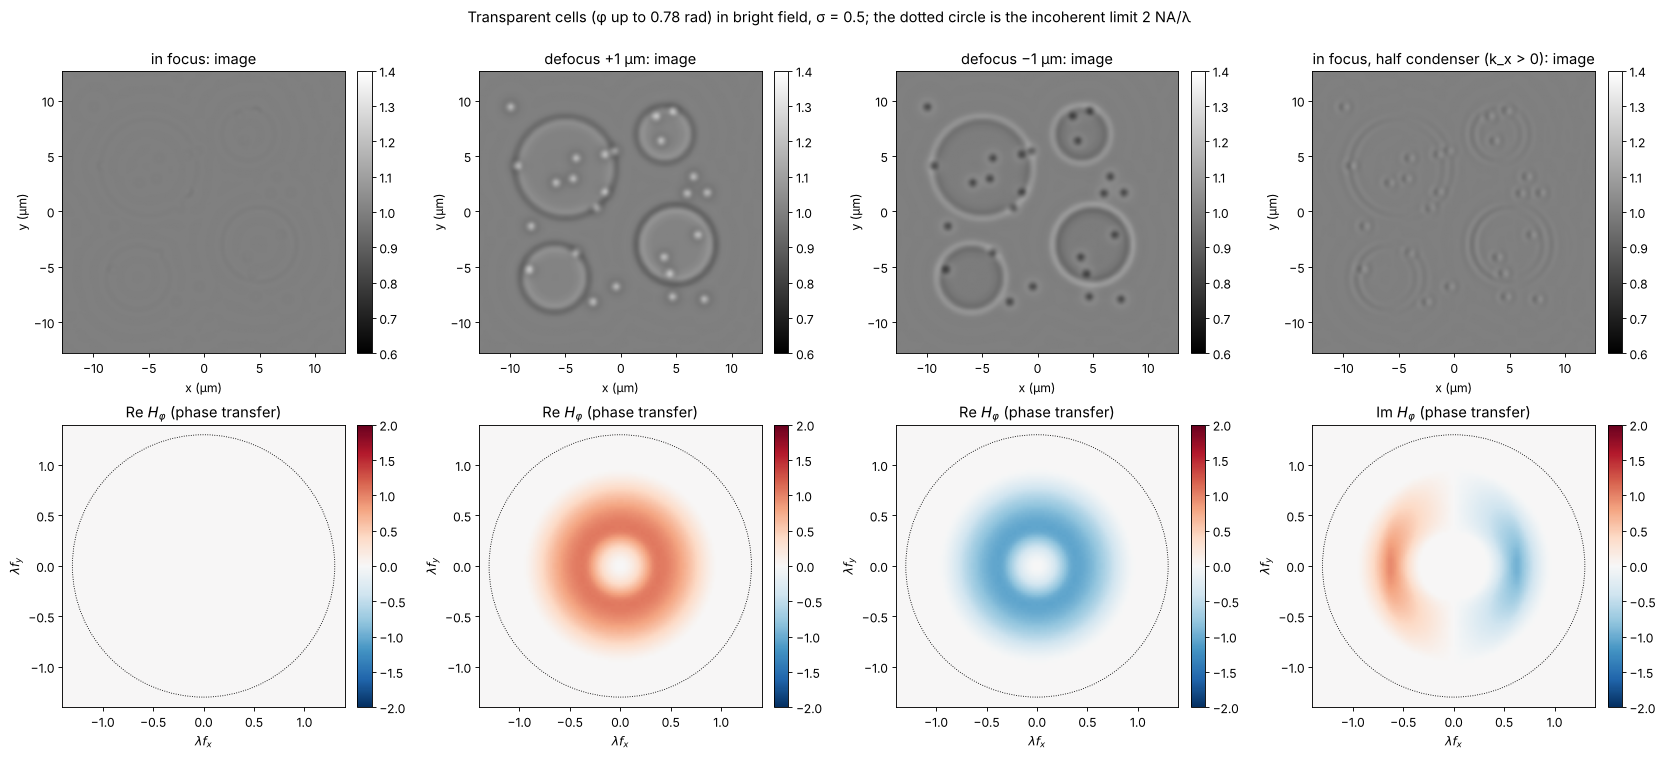

In [8]:
rng = np.random.default_rng(3)
phi = np.zeros((N, N))
for x0, y0, R, h in [(-5, 4, 4.5, 0.5), (5, -3, 3.5, 0.6), (4, 7, 2.5, 0.4), (-6, -6, 3, 0.45)]:
    phi += h*np.clip(1 - ((X - x0)**2 + (Y - y0)**2)/R**2, 0, None)**0.5
for _ in range(25):
    x0, y0 = rng.uniform(-10, 10, 2)
    phi += 0.25*np.exp(-((X - x0)**2 + (Y - y0)**2)/(2*0.2**2))
cell = np.exp(1j*phi)

sigma0 = 0.5
src_full = mic.source_points(x, y, wl, sigma0*NA)
kx_s, ky_s, w_s = src_full
half = kx_s > 0
src_half = (kx_s[half], ky_s[half], np.ones(half.sum())/half.sum())
dz = 1.0
cases = [("in focus", src_full, 0.0),
         (f"defocus +{dz:g} µm", src_full, dz),
         (f"defocus −{dz:g} µm", src_full, -dz),
         ("in focus, half condenser (k_x > 0)", src_half, 0.0)]
fig, axes = plt.subplots(2, 4, figsize=(21, 9.4))
for j, (name, src, d) in enumerate(cases):
    P = mic.pupil(x, y, wl, NA, defocus=d)
    I = mic.abbe_image(cell, x, y, wl, NA, source=src, P=P)
    H_a, H_phi = mic.weak_object_transfer(x, y, wl, NA, source=src, P=P)
    show(axes[0, j], I, f"{name}: image", vmin=0.6, vmax=1.4)
    axes[0, j].set_xlabel("x (µm)"); axes[0, j].set_ylabel("y (µm)")
    # H_phi is real for symmetric systems and imaginary (odd) for the half condenser
    part, label = ((np.real, "Re") if np.abs(H_phi.real).max() >= np.abs(H_phi.imag).max()
                   else (np.imag, "Im"))
    show(axes[1, j], part(H_phi), label + r" $H_\varphi$ (phase transfer)", cmap="RdBu_r",
         ext=na_extent, vmin=-2, vmax=2)
    pupil_circle(axes[1, j], 2*NA, color="k", lw=0.8, ls=":")
    axes[1, j].set_xlim(-1.4, 1.4); axes[1, j].set_ylim(-1.4, 1.4)
    axes[1, j].set_xlabel(r"$\lambda f_x$"); axes[1, j].set_ylabel(r"$\lambda f_y$")
fig.suptitle(f"Transparent cells (φ up to {phi.max():.2f} rad) in bright field, σ = {sigma0}; the dotted circle "
             f"is the incoherent limit 2 NA/λ", y=1.0)
plt.tight_layout()
print(f"in focus: image contrast std = {np.std(mic.abbe_image(cell, x, y, wl, NA, source=src_full)):.4f} "
      f"(only from the second order phi^2 terms)")

In focus the cells are almost invisible: what is left comes from the
second order terms in $\varphi$ and from the granules whose finest detail
is cut off by the pupil (the part of the light diffracted outside the
pupil is lost, which turns a phase into a weak amplitude signal). Defocus
makes the cells appear dark or bright depending on its sign, with
halos at the edges: the familiar look of a slightly defocused bright
field microscope, which experienced users rely on. Half a condenser gives
a relief image of $\partial\varphi/\partial x$, with an antisymmetric
phase transfer function. Neither image is proportional to $\varphi$
itself; notebook [53](53_phase_contrast_dic.ipynb) shows how Zernike's
phase plate achieves that and what its halo costs.

## Summary

- The image is the interference of the **diffraction orders that pass the
  pupil**: a period $p$ is imaged only if at least two orders pass, i.e.
  $p \ge \lambda/(\mathrm{NA}+\mathrm{NA}_c)$ (`grating_cutoff()`);
  filtering the orders in the back focal plane changes the image at will
  (Abbe, Porter).
- **Köhler illumination** is a set of mutually incoherent plane waves;
  `abbe_image()` adds their coherent images. The partial coherence
  factor $\sigma$ moves the transfer from the coherent step (cutoff
  $\mathrm{NA}/\lambda$) to the incoherent MTF (cutoff $2\mathrm{NA}/\lambda$);
  `weak_object_transfer()` gives it for any condenser and pupil and
  matches the full simulation.
- Coherent images ring at edges and need a larger distance to separate two
  points; $\sigma \approx 1$ approaches incoherent imaging.
- Weak **phase objects are invisible in focus** for symmetric systems.
  Defocus or asymmetric illumination create phase contrast, but not
  proportional to the phase; that is the subject of the next notebook.

In [9]:
print(f"run time {time.time() - t_start:.0f} s")

run time 218 s


## References

- E. Abbe, "Beiträge zur Theorie des Mikroskops und der mikroskopischen Wahrnehmung", Arch. Mikrosk. Anat. 9, 413-468 (1873).
- A. Köhler, "Ein neues Beleuchtungsverfahren für mikrophotographische Zwecke", Z. wiss. Mikrosk. 10, 433-440 (1893).
- A. B. Porter, "On the diffraction theory of microscopic vision", Phil. Mag. 11, 154-166 (1906).
- H. H. Hopkins, "On the diffraction theory of optical images", Proc. R. Soc. Lond. A 217, 408-432 (1953).
- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University Press (1999), sections 8.6 and 10.5.
- J. W. Goodman, *Introduction to Fourier Optics*, 4th ed., W. H. Freeman (2017), chapter 7.
- N. Streibl, "Three-dimensional imaging by a microscope", J. Opt. Soc. Am. A 2, 121-127 (1985).
- D. K. Hamilton and C. J. R. Sheppard, "Differential phase contrast in scanning optical microscopy", J. Microsc. 133, 27-39 (1984).
- L. Tian and L. Waller, "Quantitative differential phase contrast imaging in an LED array microscope", Opt. Express 23, 11394-11403 (2015).
- J. Mertz, *Introduction to Optical Microscopy*, 2nd ed., Cambridge University Press (2019).